# Standalone lunar soil properties

**Question:** which soil-property differences and associations are supported by the available historical samples, and which descriptors could inform a later environmental comparison?

This study compares returned Apollo soils and the existing Apollo 15 penetrometer records. Surveyor evidence is an external qualitative comparison, not a fabricated numerical soil cohort. No coordinates/site joins, engineering-response model, new scoring domain, thresholds or weights are introduced. Historical mission success is not a soil-safety label.

Missing values, sieve fractions, sample identities and source pages remain explicit. Nominal p-values and resampling intervals are exploratory; related subsamples and closed chemical percentages limit inference.

In [1]:
from pathlib import Path
import os, sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "darrel stuff/EDA").is_dir())
STAGE = ROOT / "darrel stuff/EDA/Moon/Stage3_Requirements"
sys.path.insert(0, str(STAGE))
from stage3_soil_eda import execute
PDF = Path("D:/projects/NASA Dataset/soils_hb.pdf")
PDF_PYTHON = os.environ.get("SOIL_PDF_PYTHON", "python")  # Must contain pypdf.
folder, findings = execute(PDF, pdf_python=PDF_PYTHON)


{
  "output": "C:\\Darrel\\Self-Projects\\1 group proj\\NASA-Space-Apps-Challenge-2026\\darrel stuff\\data\\processed\\analysis\\subject_soil\\20261113T053529630638Z_f65c49",
  "samples": 168,
  "support": {
    "Is_FeO": 139,
    "Mz_um": 75,
    "Md_um": 22,
    "agglutinates_percent": 60,
    "SiO2": 115,
    "TiO2": 127,
    "Al2O3": 131,
    "Cr2O3": 92,
    "FeO": 131,
    "MnO": 122,
    "MgO": 126,
    "CaO": 131,
    "Na2O": 129,
    "K2O": 119,
    "P2O5": 96
  }
}


In [2]:
import pandas as pd
from IPython.display import display, Image
print(findings["base_conclusion"])
display(pd.read_csv(folder / "mission_property_summary.csv"))
display(pd.read_csv(folder / "association_uncertainty.csv"))
display(pd.read_csv(folder / "penetrometer_run_summary.csv"))


Soil properties can describe distinct historical sample regimes and interrelated features. These data do not identify an effect on mission/base environmental operability or an optimum soil type.


,mission,feature,samples,supported,median,minimum,maximum,q25,q75,missing_fraction
0,11,Al2O3,7,4,13.21,12.80,13.600,13.1075,13.30750,0.428571
1,11,CaO,7,4,12.05,11.94,12.400,12.0225,12.13750,0.428571
2,11,Cr2O3,7,4,0.30,0.30,0.305,0.3000,0.30125,0.428571
3,11,FeO,7,4,15.83,15.34,16.200,15.7075,15.92250,0.428571
4,11,Is_FeO,7,4,75.00,69.00,78.000,73.5000,75.75000,0.428571
...,...,...,...,...,...,...,...,...,...,...
85,17,Na2O,68,41,0.38,0.20,0.470,0.3500,0.41000,0.397059
86,17,P2O5,68,37,0.09,0.04,0.890,0.0700,0.13600,0.455882
87,17,SiO2,68,41,42.67,19.90,45.560,40.3400,44.51000,0.397059
88,17,TiO2,68,41,3.83,1.39,10.310,1.8600,7.68000,0.397059


,x,y,n_samples,bootstrap_rho_low,bootstrap_rho_high,finite_bootstrap_replicates,mission_adjusted_rank_association,within_mission_permutation_p,scope,permutation_bh_q
0,Is_FeO,Mz_um,70,-0.369637,0.084519,2000,-0.232309,0.028486,"conditional sample-resampling sensitivity, NOT...",0.035607
1,Is_FeO,agglutinates_percent,47,0.456689,0.858370,2000,0.719082,0.000500,"conditional sample-resampling sensitivity, NOT...",0.000833
2,Mz_um,Md_um,11,0.305556,1.000000,2000,0.723723,0.067966,"conditional sample-resampling sensitivity, NOT...",0.067966
3,FeO,Al2O3,130,-0.968147,-0.837943,2000,-0.740512,0.000500,"conditional sample-resampling sensitivity, NOT...",0.000833
4,FeO,TiO2,126,0.697721,0.852839,2000,0.794419,0.000500,"conditional sample-resampling sensitivity, NOT...",0.000833


,run,mission,geometry,records,numeric_depth_stress_records,reported_depth_min_cm,reported_depth_max_cm,reported_stress_max_kPa,depth_stress_rank_association,documented_depth_limitation,documented_trench_collapse,interpretation
0,1,15,cone,16,15,2.84,9.14,344.0,0.629928,False,False,"within-run loading path, NOT independent soil ..."
1,2,15,cone,18,17,8.19,10.87,344.0,0.661738,False,False,"within-run loading path, NOT independent soil ..."
2,3,15,cone,16,15,1.10,6.30,342.0,0.665473,True,False,"within-run loading path, NOT independent soil ..."
3,4,15,cone,18,17,8.51,11.97,347.0,0.665428,True,False,"within-run loading path, NOT independent soil ..."
4,5,15,plate,11,10,8.35,9.77,34.1,0.582046,True,False,"within-run loading path, NOT independent soil ..."
5,6,15,plate,15,14,2.05,6.93,34.3,0.551834,True,True,"within-run loading path, NOT independent soil ..."


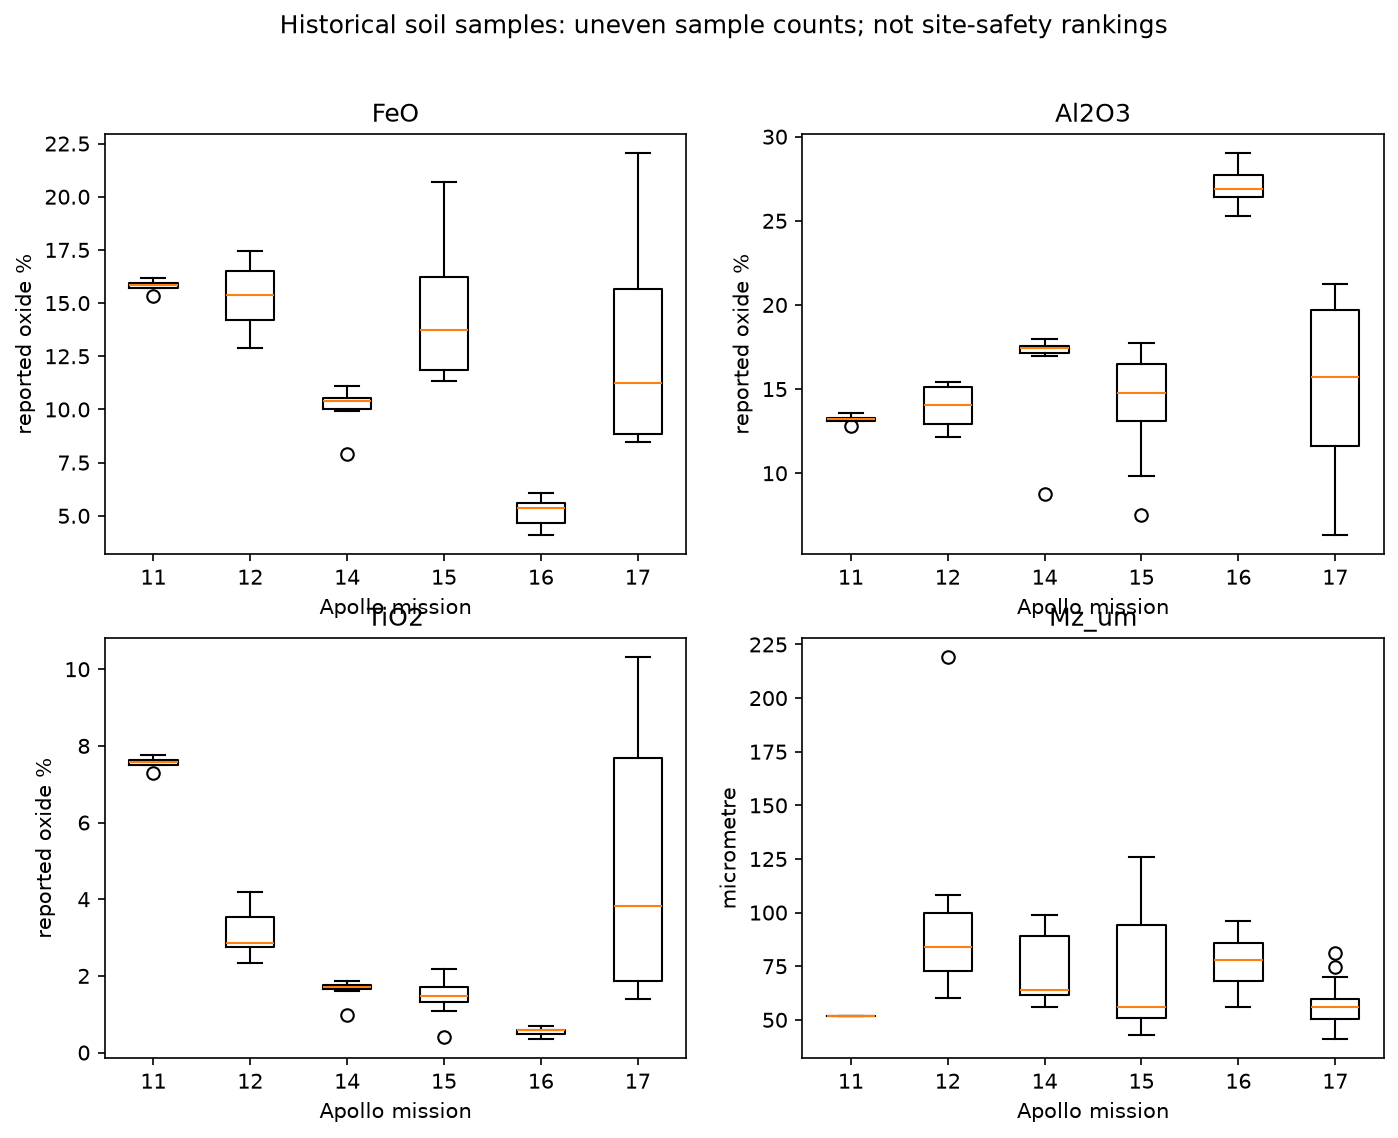

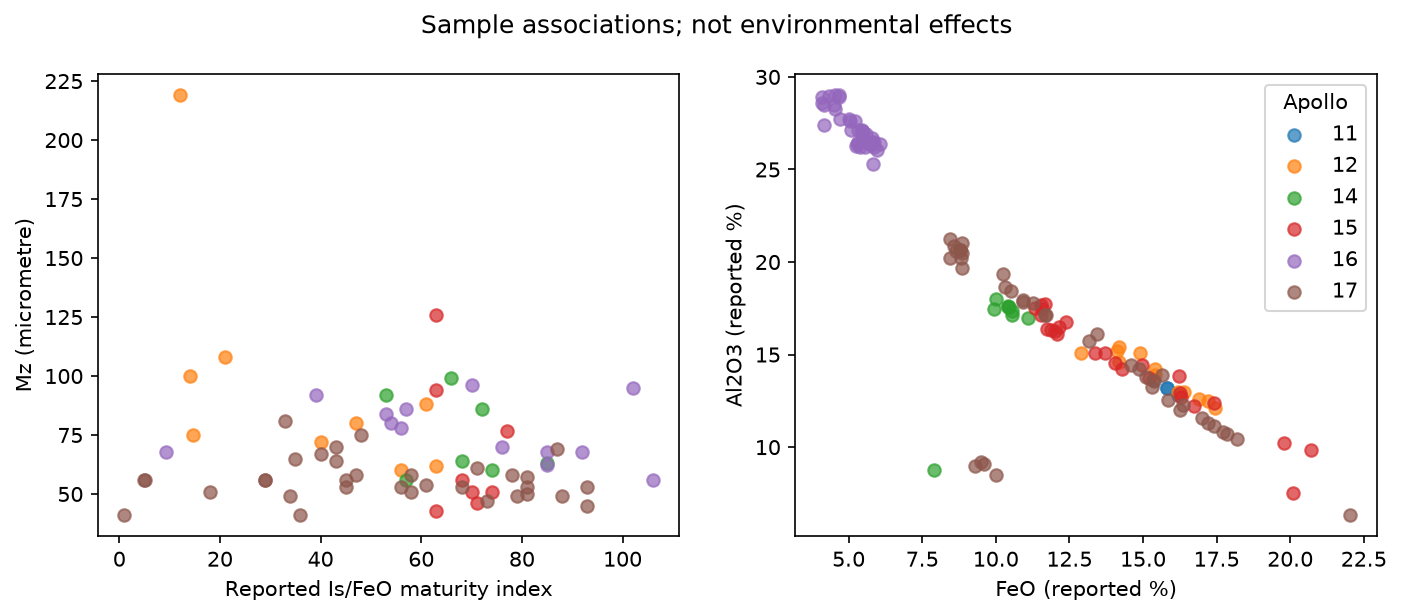

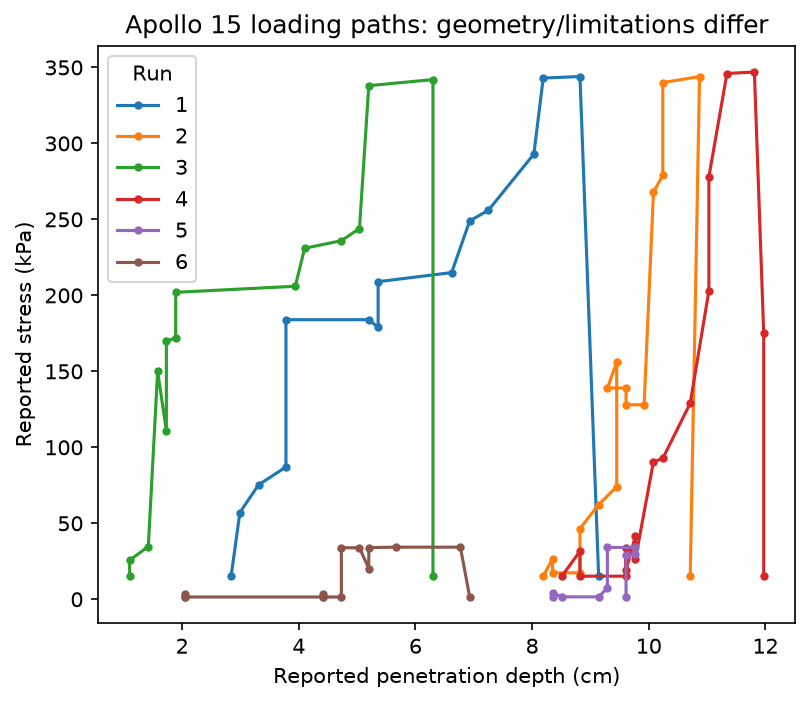

,feature,fields,potential_use,guard,adoption_status,environmental_effect_identified,scoring_direction,threshold,weight
0,soil_composition_vector,"FeO, TiO2, Al2O3 and remaining reported oxides","condition/regime context, not a scalar good/ba...",compositional dependence; calibration and pros...,research_only_not_adopted,False,unresolved,not_established,not_established
1,soil_grain_size,"Mz_um, Md_um, sieve support",candidate continuous descriptors after measure...,Mz/Md correlated; mean size is NOT respirable ...,research_only_not_adopted,False,unresolved,not_established,not_established
2,soil_maturity,Is_FeO; agglutinates with declared fraction,"maturity/context descriptor, NOT higher-is-saf...","no outcome-calibrated direction, threshold or ...",research_only_not_adopted,False,unresolved,not_established,not_established
3,soil_mechanical_response,load/stress/depth with geometry and limitation...,reference evidence only in this standalone ana...,different geometries and measurement limitatio...,research_only_not_adopted,False,unresolved,not_established,not_established


In [3]:
for name in ["mission_distributions.png", "property_associations.png", "penetrometer_loading_paths.png"]:
    display(Image(filename=str(folder / name)))
display(pd.read_csv(folder / "pipeline_research_candidates.csv"))


## Interpretation boundaries

- Compare sample distributions and pairwise support, not just mission averages. Within-mission and leave-one-mission-out tables expose pooled-comparison sensitivity.
- Chemistry is compositional. Is/FeO has an FeO denominator; grain-size descriptors and maturity indicators can also be redundant. Correlation is not independent evidence to add multiple scoring weights.
- The handbook covers non-core Apollo samples, not Surveyor samples or prospective polar sites. Native table blanks remain missing; ambiguous values are held rather than guessed.
- Penetrometer loading paths have different tool geometries, documented depth limitations and a collapse case. They are not independent replicated soil-type experiments.
- There is no matched environmental outcome in this standalone dataset. A best soil type, safe threshold, scoring direction or weight is **not established**.

See the soil section in `EDA_Notes.md` for findings and candidate descriptors. Source text, numeric tables, extraction holds and provenance are stored under `darrel stuff/data/processed/analysis/subject_soil/`.